WEEK 1: LAB 0 — SETTING UP THE DSP LABORATORY

Module: Digital Signal Processing

Unit 1: Introduction to DSP and its role in AI
Student Name: Yese Stanley Nonya

Registration Number: 240242467843

Institution: Dar es Salaam Institute of Technology

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io.wavfile as wavfile
import os

print("DSP Laboratory Environment Ready!")

DSP Laboratory Environment Ready!


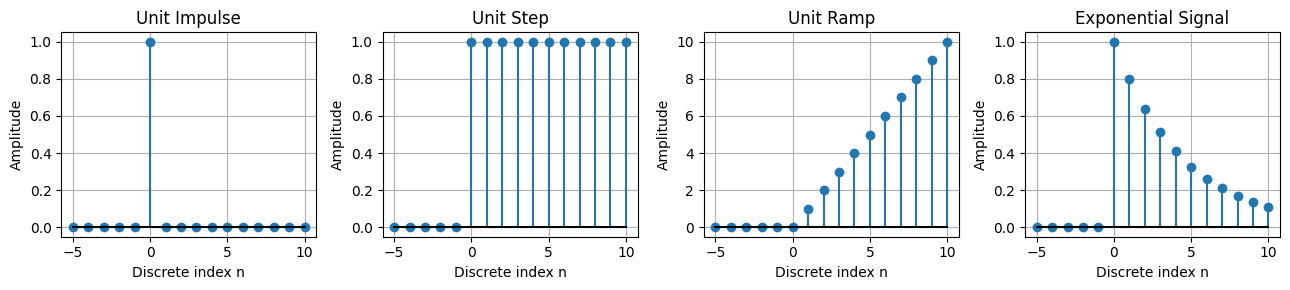

In [3]:

# TASK 1.1: GENERATING ELEMENTARY DISCRETE-TIME SIGNALS

import numpy as np
import matplotlib.pyplot as plt

# Define discrete-time index
n = np.arange(-5, 11)

# Generate elementary signals
delta = (n == 0).astype(float)       # Unit impulse
step = (n >= 0).astype(float)         # Unit step
ramp = n * step                      # Unit ramp
expo = 0.8**n * step                 # Exponential signal

# Create four subplots
fig, axes = plt.subplots(1, 4, figsize=(13, 3))

signals = [delta, step, ramp, expo]
titles = ["Unit Impulse", "Unit Step",
          "Unit Ramp", "Exponential Signal"]

# Plot each signal
for ax, x, title in zip(axes, signals, titles):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("Discrete index n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()


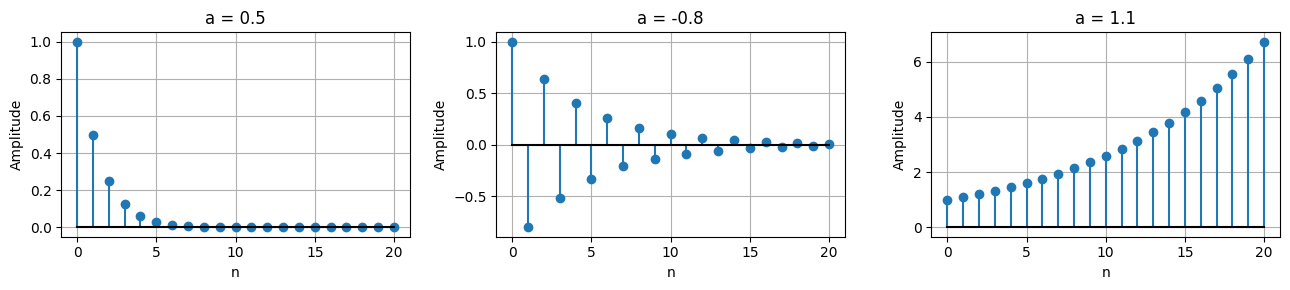

In [4]:

# TASK 1.2 (A): EXPONENTIAL SIGNALS

n = np.arange(0, 21)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))

for ax, a in zip(axes, a_values):

    x = a**n

    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()


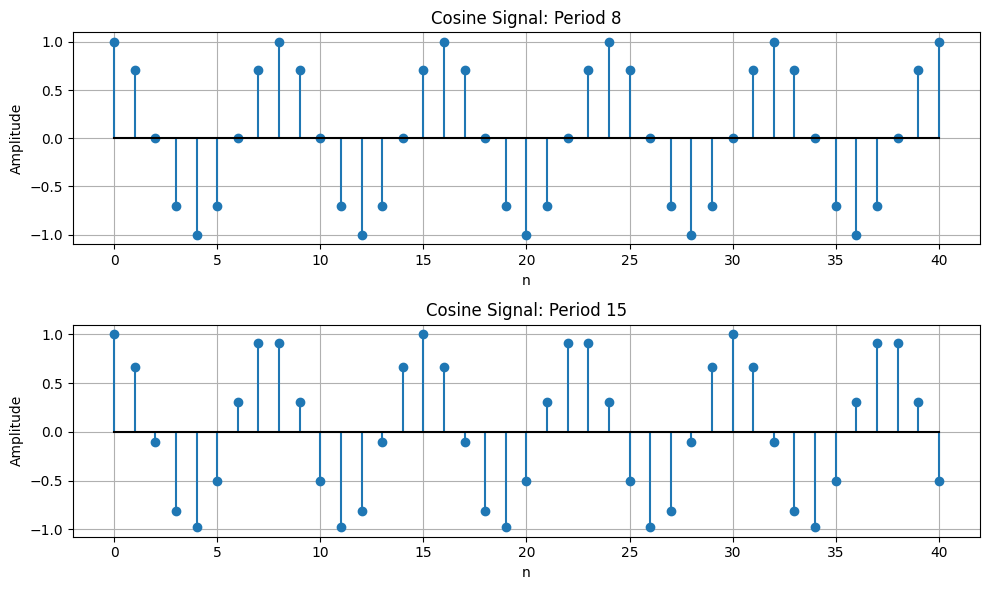

In [5]:

# TASK 1.2 (B): COSINE SIGNALS

n = np.arange(0, 41)

x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].stem(n, x1, basefmt="k-")
axes[0].set_title("Cosine Signal: Period 8")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].stem(n, x2, basefmt="k-")
axes[1].set_title("Cosine Signal: Period 15")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()


Sampling rate = 48000 Hz
Duration = 10.24 seconds
Number of samples = 491520


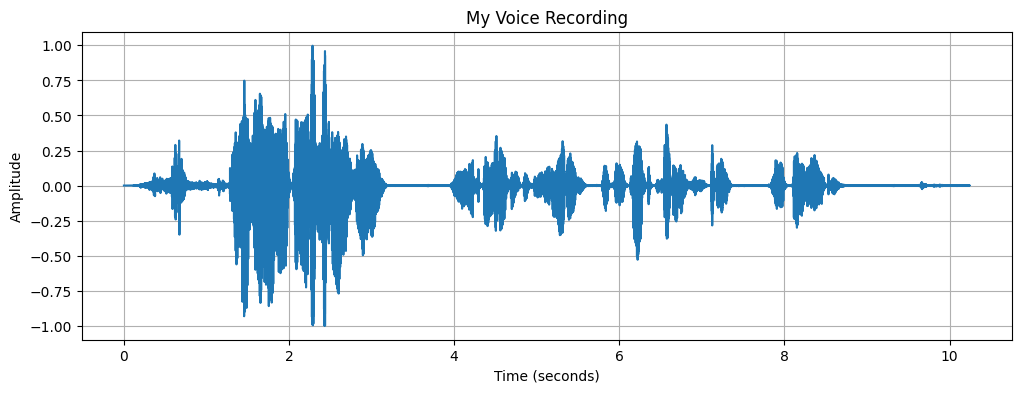

In [6]:

# TASK 1.3: AUDIO SIGNAL PROCESSING

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display
import os

fname = "my_voice.wav"

if os.path.exists(fname):

    # Read the audio file
    fs, x = wavfile.read(fname)

    # Convert stereo audio to mono
    if x.ndim > 1:
        x = x.astype(float).mean(axis=1)

    # Normalize audio
    x = x.astype(float)

    if np.max(np.abs(x)) > 0:
        x = x / np.max(np.abs(x))

else:
    # Generate a test signal if recording is unavailable
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2*np.pi*440*t) * np.exp(-t)

# Generate time axis
t = np.arange(len(x)) / fs

# Display audio information
print(f"Sampling rate = {fs} Hz")
print(f"Duration = {len(x)/fs:.2f} seconds")
print(f"Number of samples = {len(x)}")

# Plot audio signal
plt.figure(figsize=(12, 4))
plt.plot(t, x)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("My Voice Recording")
plt.grid(True)
plt.show()

# Play the recording
display(Audio(x, rate=fs))
